# TSMOM ครั้งที่ 2: universe 12 ตัว (D1)

**ล็อกก่อนรัน ห้ามแก้หลังเห็นผล**
- รายชื่อ: EURUSD, USDJPY, GBPUSD, AUDUSD, USDCAD | XAUUSD, XAGUSD, COPPER | US500, DE40, UK100, JPN225
- ตัวไหนโหลดไม่ได้หรือมีข้อมูล < 5 ปี ตัดออก **ห้ามหาตัวแทนหลังเห็นผล**
- เกณฑ์ผ่านเดิมทุกข้อ (ใน `project/strategy/tsmom.py`): net Sharpe > 0.4, ปีที่กำไร >= 60%, max DD < 25%, stress (spread x2) Sharpe > 0.3
- lookback 126/189 ดูความเสถียรเท่านั้น ห้ามเลือกตัวดีสุด
- นับจำนวนที่ลอง: ตระกูล TSMOM **ครั้งที่ 2** (ครั้งที่ 1 = 3 ตัว ไม่ผ่าน Sharpe 0.25) รวมกับ MA+ADX 9 คู่ = 11

In [1]:
%load_ext autoreload
%autoreload 2

In [3]:
from datetime import datetime

import MetaTrader5 as mt5
from project.Untility.data_loader import DataLoader
from project.strategy.tsmom import evaluate_pass, run_tsmom, metrics

SYMBOLS = ["EURUSD", "USDJPY", "GBPUSD", "AUDUSD", "USDCAD",
           "XAUUSD", "XAGUSD", "COPPER",
           "US500", "DE40", "UK100", "JPN225"]
MIN_YEARS = 5
DATE_FROM, DATE_TO = datetime(2010, 1, 1), datetime(2024, 1, 1)

data, points, dropped = {}, {}, {}
for s in SYMBOLS:
    try:
        loader = DataLoader(s, mt5.TIMEFRAME_D1)
        df = loader.load_with_date(DATE_FROM, DATE_TO)
        years = (df.index.max() - df.index.min()).days / 365.25
        if years < MIN_YEARS:
            dropped[s] = f"ข้อมูลแค่ {years:.1f} ปี"
            continue
        data[s], points[s] = df, loader.point()
        print(f"{s:8s} {len(df):5d} แท่ง  {df.index.min().date()} -> {df.index.max().date()}  point {points[s]}")
    except Exception as e:
        dropped[s] = f"{type(e).__name__}: {e}"
print("\nตัดออก:", dropped if dropped else "ไม่มี")
print("ใช้จริง", len(data), "ตัว")

EURUSD    3636 แท่ง  2010-01-04 -> 2023-12-29  point 1e-05
USDJPY    3636 แท่ง  2010-01-04 -> 2023-12-29  point 0.001
AUDUSD    3636 แท่ง  2010-01-04 -> 2023-12-29  point 1e-05
USDCAD    3636 แท่ง  2010-01-04 -> 2023-12-29  point 1e-05
XAUUSD    3606 แท่ง  2010-01-04 -> 2023-12-29  point 0.01
XAGUSD    3605 แท่ง  2010-01-04 -> 2023-12-29  point 0.001
US500     2947 แท่ง  2012-08-06 -> 2023-12-29  point 0.01
DE40      2904 แท่ง  2012-08-06 -> 2023-12-29  point 0.01

ตัดออก: {'GBPUSD': 'ValueError: No data returned from MetaTrader5 for the date range', 'COPPER': 'ข้อมูลแค่ 0.6 ปี', 'UK100': 'ข้อมูลแค่ 2.2 ปี', 'JPN225': 'ข้อมูลแค่ 4.7 ปี'}
ใช้จริง 8 ตัว


In [4]:
# ผลตามเกณฑ์ที่ล็อกไว้ (รันครั้งเดียว อ่านผล ไม่ปรับแล้วรันซ้ำ)
out = evaluate_pass(data, points)
for k, v in out.items():
    print(k, ":", v)

base : {'sharpe': 0.24, 'return_%': 16.9, 'maxdd_%': 13.2, 'positive_years_%': 54.0, 'years': 13}
stress_spread_x2 : {'sharpe': 0.23, 'return_%': 16.3, 'maxdd_%': 13.2, 'positive_years_%': 54.0, 'years': 13}
lookback_stability_sharpe : {126: 0.21, 189: 0.15, 252: 0.24}
checks : {'sharpe > 0.4': False, 'positive years >= 60%': False, 'max DD < 25%': True, 'stress sharpe > 0.3': False}
pass : False
n_assets : 8


time
2011    -1.2
2012    -3.4
2013    13.0
2014     6.5
2015     6.1
2016    -8.6
2017     7.0
2018    -0.5
2019    -0.4
2020     1.0
2021     0.3
2022     1.3
2023    -3.7
Name: return_%, dtype: float64
ต้นทุนรวม (สัดส่วนของทุน): 0.0044
ผลก่อนหักต้นทุน: {'sharpe': 0.24, 'return_%': 17.4, 'maxdd_%': 13.2, 'positive_years_%': 54.0, 'years': 13}
ช่วงทดสอบ: 2011-01-03 -> 2023-12-28


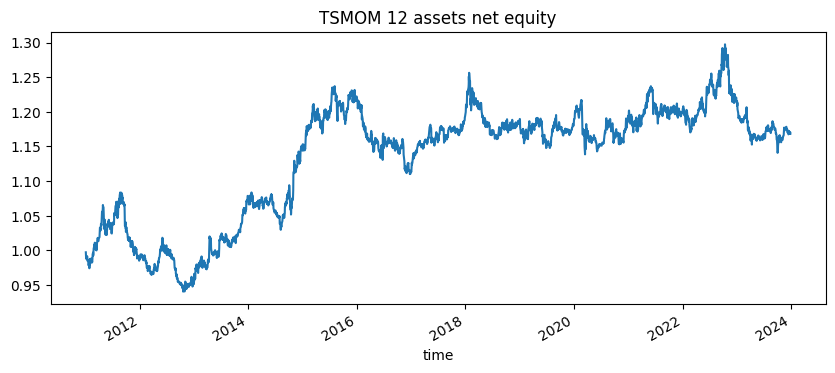

In [5]:
# รายละเอียด (ดูเฉย ๆ ไม่ใช้ปรับกลยุทธ์)
res = run_tsmom(data, points)
res["equity"].plot(title="TSMOM 12 assets net equity", figsize=(10, 4))
r = res["returns"]
print(((1 + r).groupby(r.index.year).prod() - 1).mul(100).round(1).rename("return_%"))
print("ต้นทุนรวม (สัดส่วนของทุน):", round(float(res["cost"].sum()), 4))
print("ผลก่อนหักต้นทุน:", metrics(res["gross_returns"]))
print("ช่วงทดสอบ:", r.index.min().date(), "->", r.index.max().date())